In [2]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets
import json

today = date.today()

**Functions**

In [6]:
data_dir = '../../../data/'

# Given a scale, build a path name for the search space
def build_search_space_path(scale):
    path = os.path.join(data_dir, 'regions_{}kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'.format(scale))
    return path


"""
# Given a scale, build a path name for the query region
def build_query_path(scale):
    path = os.path.join(data_dir, 'regions_{}kb_CT20230412.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'.format(scale))
    return path
"""


# Given a scale, build a path name for the tabix query
def build_tabix_path(scale):
    # path = os.path.join(data_dir, 'hg38.{}kb.regions.CT20230412.sorted.rownum4.bed.gz'.format(scale))
    path = 'https://resources.altius.org/~ctrader/public/genomic_narration/indexed/hg38.{}kb.regions.CT20230427.sorted.rownum4.factorranks5t38.bed.gz'.format(scale)
    return path


# Load search space data from a given scale
def load_ranks(search_space_path):
    search_space = np.load(search_space_path)
    percents = search_space['percentiles']
    coords = search_space['coordinates']
    return percents, coords


# load search spaces for all scales into dict
seach_spaces = {}
for scale in [1, 2, 5, 10, 15, 25, 50, 75, 100]:
    seach_spaces[scale] = load_ranks(build_search_space_path(scale))
    
# Functions for narration

def tabix_query(filename, query):
    # Use subprocess with tabix and return hits
    process = Popen(['tabix', '-f', filename, query], stdout=PIPE)

    hits = []
    for line in process.stdout:
        hits.append(np.char.decode(line.strip().split()))
    hits = np.array(hits)
    return hits


"""
# determine roi from query coordinates
def load_roi(genomic_location, tabix_file_path):
    global roi

    # determine chromosome, start, and end from query
    query_start_end = genomic_location.split(':')[1].split('-')
    query_start = int(query_start_end[0])
    query_end = int(query_start_end[1])

    # retrieve possible rois
    tb = tabix.open(tabix_file_path)
    possible_coords = np.array(list(tb.querys(genomic_location)))

    # find closest roi
    start_dist = np.abs(possible_coords[:, 1].astype(int) - query_start)
    end_dist = np.abs(possible_coords[:, 2].astype(int) - query_end)
    query_region = possible_coords[np.argmin(start_dist + end_dist)]
    roi = int(query_region[3])

    return
"""

# determine roi from query coordinates
def load_roi(genomic_location, link_path):
    global roi, roi_percents, roi_coords

    # determine chromosome, start, and end from query
    query_start_end = genomic_location.split(':')[1].split('-')
    query_start = int(query_start_end[0])
    query_end = int(query_start_end[1])

    # retrieve possible rois
    possible_coords = tabix_query(link_path, genomic_location)

    # find closest roi
    start_dist = np.abs(possible_coords[:, 1].astype(int) - query_start)
    end_dist = np.abs(possible_coords[:, 2].astype(int) - query_end)
    query_region = possible_coords[np.argmin(start_dist + end_dist)]

    roi = int(query_region[3])
    roi_percents = query_region[4:].astype('float32')
    roi_coords = query_region[:3]

    return


"""
# load query ranks and coordinates
def load_ranks(query_path):
    global roi_percents, roi_coords

    # load roi ranks
    hdf5_f = h5py.File(query_path, 'r')
    roi_percents = hdf5_f['percentiles'][roi]
    roi_coords = np.char.decode(hdf5_f['coordinates'][roi])
    hdf5_f.close()
"""


# choose search space from scale options
def choose_search_space(scale):
    global percents, coords

    percents, coords = seach_spaces[scale]
    
    
# find the factors we want to search over
def setup_included_factors(included_factors_str, query_factor_thresh):
    global included_factors

    included_factors_from_str = np.int_(
        included_factors_str.strip('[').strip(']').split(',')
    )
    query_factors_above_thresh = np.where(roi_percents > query_factor_thresh)[0]

    # if no factors above threshold, search best one
    if len(query_factors_above_thresh) == 0:
        sort_order = np.argsort(-roi_percents)
        included_factors = sort_order[
            np.isin(sort_order, included_factors_from_str)
        ][:1]
    else:
        included_factors = included_factors_from_str[
            np.isin(included_factors_from_str, query_factors_above_thresh)
        ]
    # included_factors=np.arange(34)

# given our roi, find the similar regions
def find_most_similar_region_indices(num_similar_regions):
    global top_regions, top_region_coords, top_regions_sim, top_regions_per, query_factor_order, target_factors, pval, Z, query_sim_prod_ranks
    (top_regions, top_region_coords, top_regions_sim,
     top_regions_per, query_factor_order,
     target_factors, pval,
     Z, query_sim_prod_ranks) = simsearch(roi_percents, percents, roi, roi_coords, coords, included_factors, num_similar_regions)


# generate roiURL to view similar regions in index browser
def setup_roiURLs(get_roiURL, target_factors):
    global roiURLs
    roiURLs = []
    for dl in range(1, len(included_factors) + 1):
        if get_roiURL == 'Tru':  # 'True'
            # roiURLs.append('roiURL not available')
            roiURLs.append(roiURL(roi, top_region_coords[dl-1],
                                  dl, '_'.join(target_factors.astype(str))))
        else:
            roiURLs.append('roiURL not available')


# reorder data based on ranks in query region/roi
def reorder_by_query_region():
    global return_top_regions_per, return_pval, return_Z
    return_top_regions_per = top_regions_per[:, :, query_factor_order]
    return_pval = pval[:, query_factor_order]
    return_Z = Z[:, query_factor_order]
    
# build array of objects for roi and each similar region at each detail level
def generate_result_array(num_similar_regions):
    global return_arr_full
    return_arr_full = []
    for dl in range(len(included_factors)):
        # for the roi, return results as json array
        # each element is an object of scores for each metric
        return_arr = []
        for rank in range(num_similar_regions + 1):
            coord = top_region_coords[dl, rank]
            region_dict = {
                'rank': rank,
                'coordinates': coord[0] + ':' + coord[1] + '-' + coord[2],
                'region_ind': int(top_regions[dl, rank]),
                'score': float(top_regions_sim[dl, rank]),
                'percentiles': return_top_regions_per[dl, rank].tolist(),
                'prod_rank': query_sim_prod_ranks[dl, rank]
            }
            if rank == 0:
                region_dict['region_ind'] = 'NA'
                region_dict['score'] = 'NA'
                region_dict['query_factor_order'] = query_factor_order.tolist()
                region_dict['target_factors'] = target_factors.tolist()
                region_dict['top_region_factor_Z_score'] = return_Z[dl].tolist()
                region_dict['top_region_factor_pval'] = return_pval[dl].tolist()
                region_dict['roiURL'] = roiURLs[dl]
                region_dict['detail_level'] = dl + 1
                # region_dict['query_prod_rank'] = query_sim_prod_ranks[dl]
            return_arr.append(region_dict)

        return_arr_full.append(return_arr)

        


FileNotFoundError: [Errno 2] No such file or directory: '../../../data/regions_1kb_CT20230427.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'

In [3]:
def load_factors(per_f):
    hdf5_f = h5py.File(per_f, 'r')
    factors = np.char.decode(hdf5_f['factors'][:])
    color = np.char.decode(hdf5_f['colors'][:])
    hdf5_f.close()
    return factors, color

datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_per_f = datadir + 'regions_1kb_CT20230412.DHS.factornormNMF.sum_enrich_corank_percentile.hdf5'
epi_per_f = datadir + 'regions_1kb_CT20230412.epilogos.statesum_rank_percentile.hdf5'

# load region percentiles
DHS_factors, DHS_color = load_factors(DHS_per_f)
epi_factors, epi_color = load_factors(epi_per_f)

factor_order = np.append(DHS_factors, epi_factors)
color_order = np.append(DHS_color, epi_color)

color_order[np.where(factor_order == 'Quies')[0]] = '#e0e0e0'

In [4]:
scale = '25'
genomic_location = 'chrX:48778015-48802844'
gene = 'GATA1'
num_similar_regions = 20
included_factors_str = '[' + ','.join(np.arange(34).astype(str)) +']'
query_factor_thresh = 0.5

In [5]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
sub_path = datadir + 'regions_' + scale + 'kb_CT20230412.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.limited_search_space_top_1000_no_overlap.npz'

percents_sub = np.load(sub_path)['percentiles']
coords_sub = np.load(sub_path)['coordinates']
chosen_factors_sub = np.load(sub_path, allow_pickle=True)['factors']

In [6]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'

gz_file_path = datadir + 'hg38.' + scale + 'kb.regions.CT20230412.sorted.rownum4.bed.gz'

roi = load_roi(genomic_location, gz_file_path)

In [7]:
datadir = '/home/ctrader/AG/NarrativeGenomics/region_narration/data/'

query_path = datadir + 'regions_' + scale + 'kb_CT20230412.DHS.factornormNMF.sum_enrich_corank.epilogos.statesum_rank.percentiles.hdf5'

hdf5_f = h5py.File(query_path, 'r')
roi_percents = hdf5_f['percentiles'][roi]
roi_coords = np.char.decode(hdf5_f['coordinates'][roi])
hdf5_f.close()

included_factors = setup_included_factors(included_factors_str, query_factor_thresh, roi_percents)

s_sub = simsearch(roi_percents, 
                  percents_sub, 
                  roi, 
                  roi_coords, 
                  coords_sub, 
                  included_factors,
                  num_similar_regions)
s_pen = simsearch_penalized(roi_percents, 
                  percents_sub, 
                  roi, 
                  roi_coords, 
                  coords_sub, 
                  included_factors,
                  num_similar_regions)

roiurls_sub = []
roiurls_pen = []
for dl in range(included_factors.shape[0]):
    roiurls_sub.append(roiURL(roi, s_sub[1][dl], dl+1, 'top_1000', scale))
    roiurls_pen.append(roiURL(roi, s_pen[1][dl], dl+1, 'top_1000', scale))

(20,)
[15  2  9 16  8 18 19  1 17  0 11  5  3  6  7 12 24 13  4 25]
(20,)
[15  2  9 16  8 18 19  1 17  0 11  5  3  6  7 12 24 13  4 25]


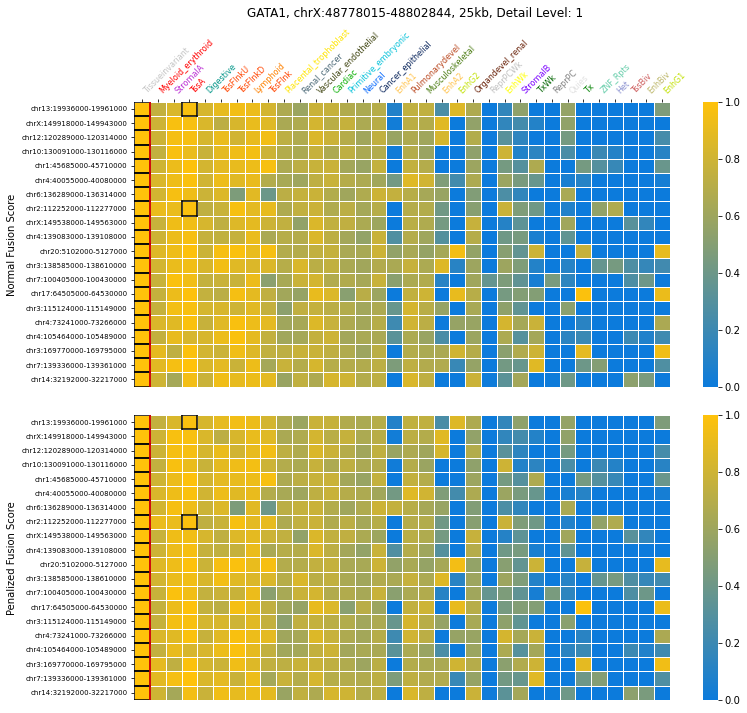

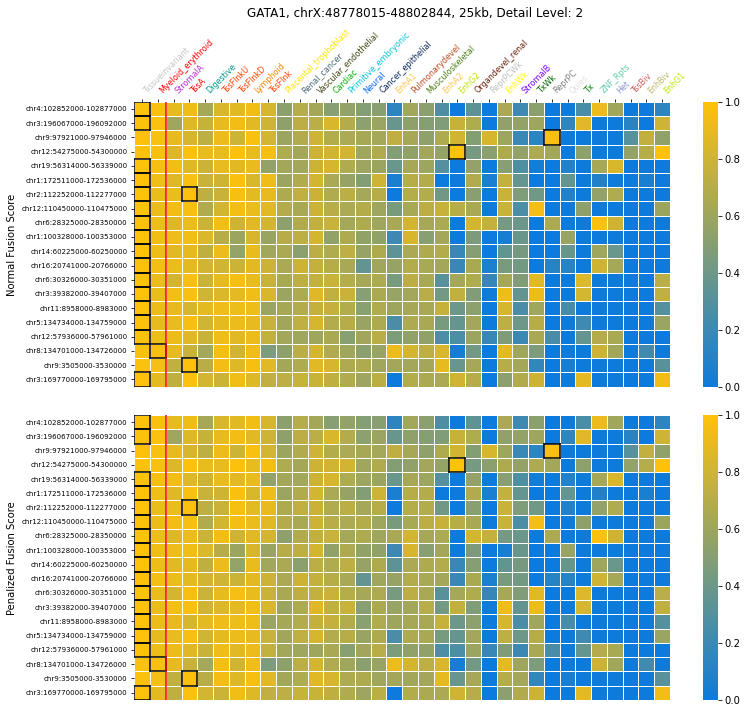

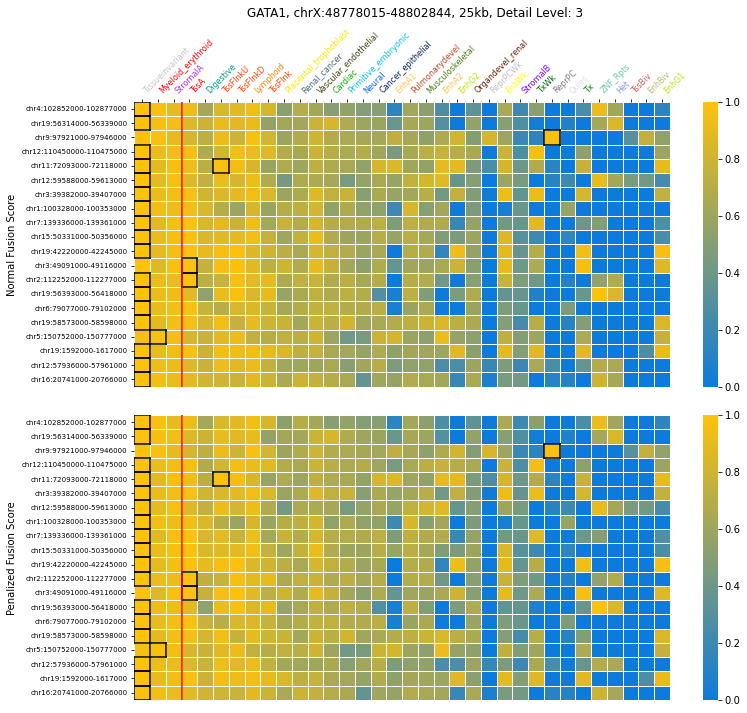

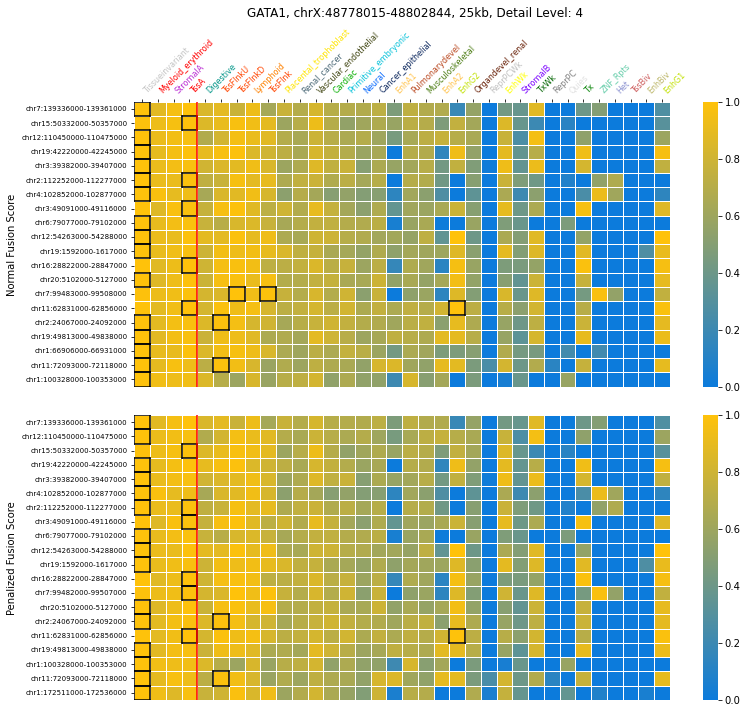

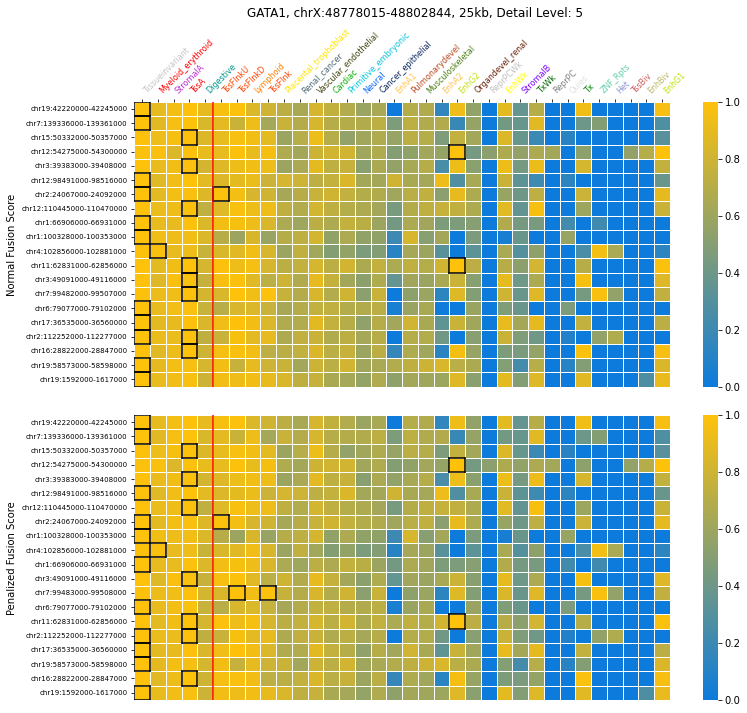

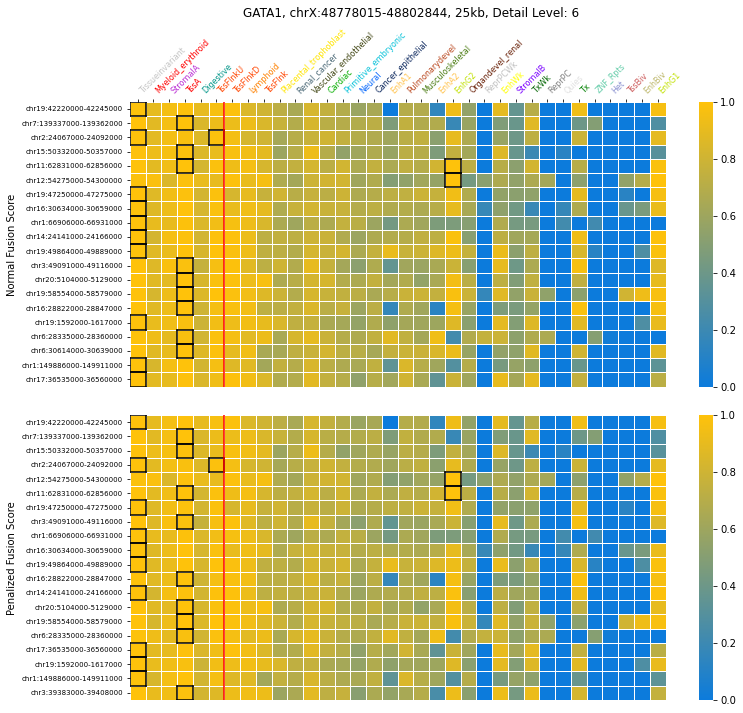

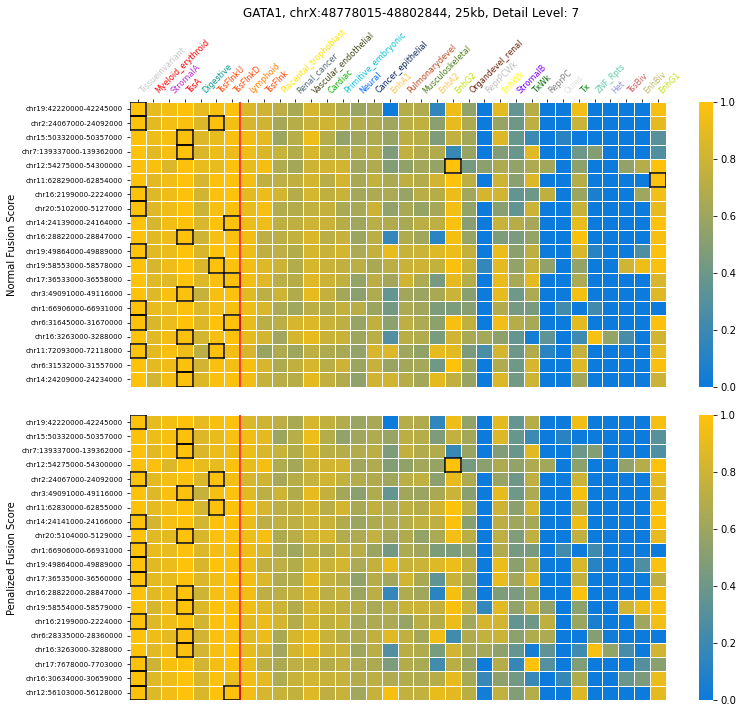

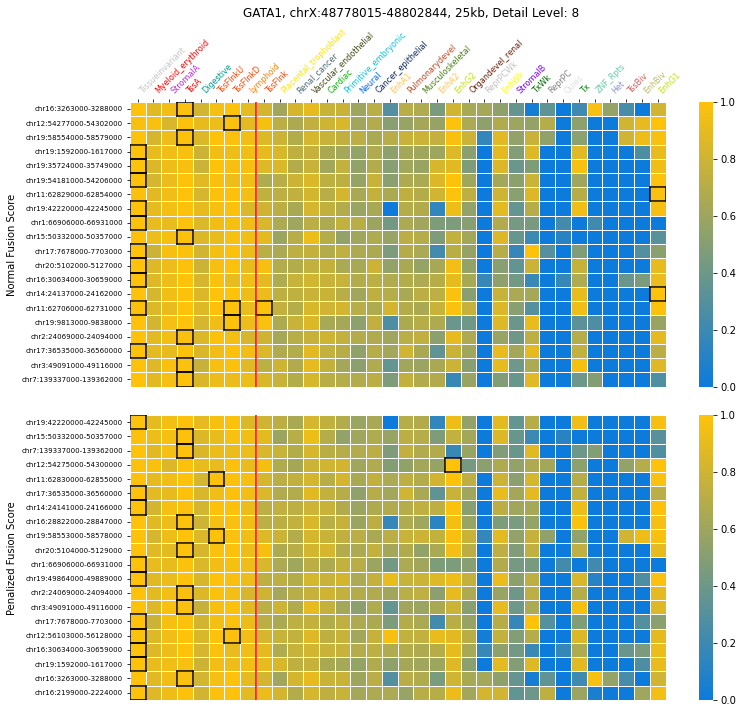

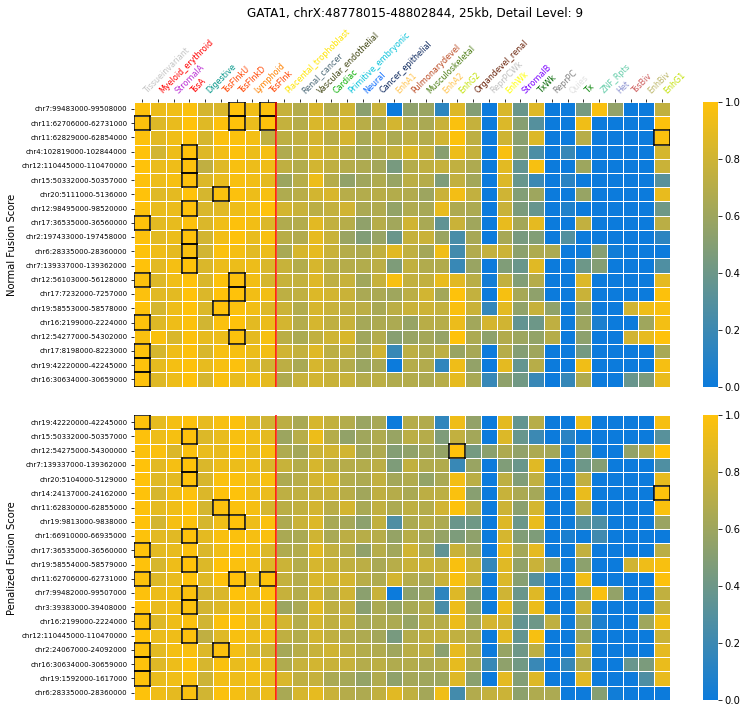

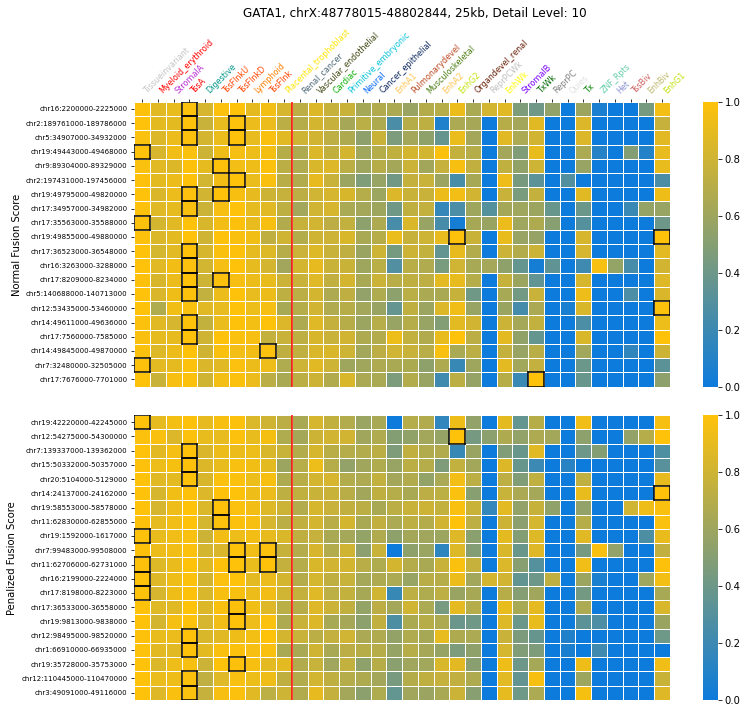

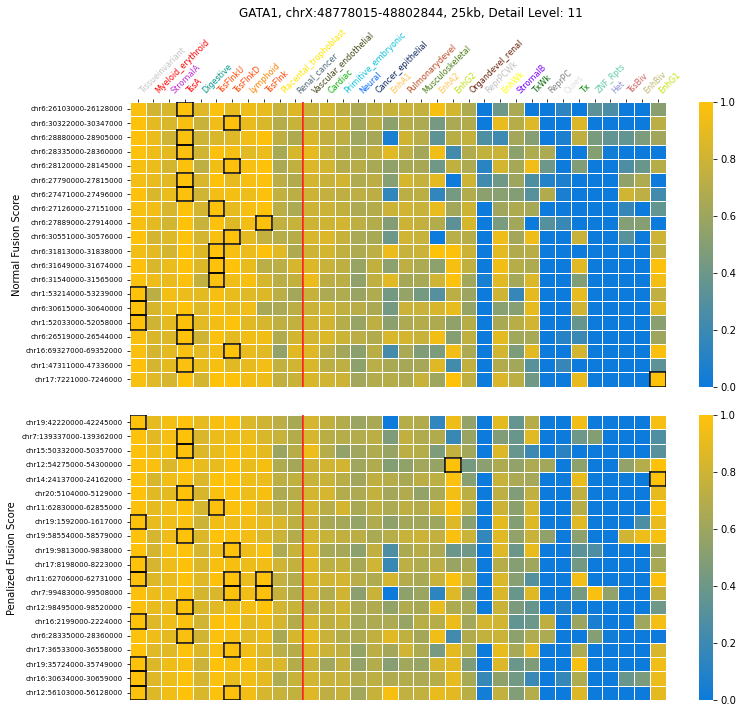

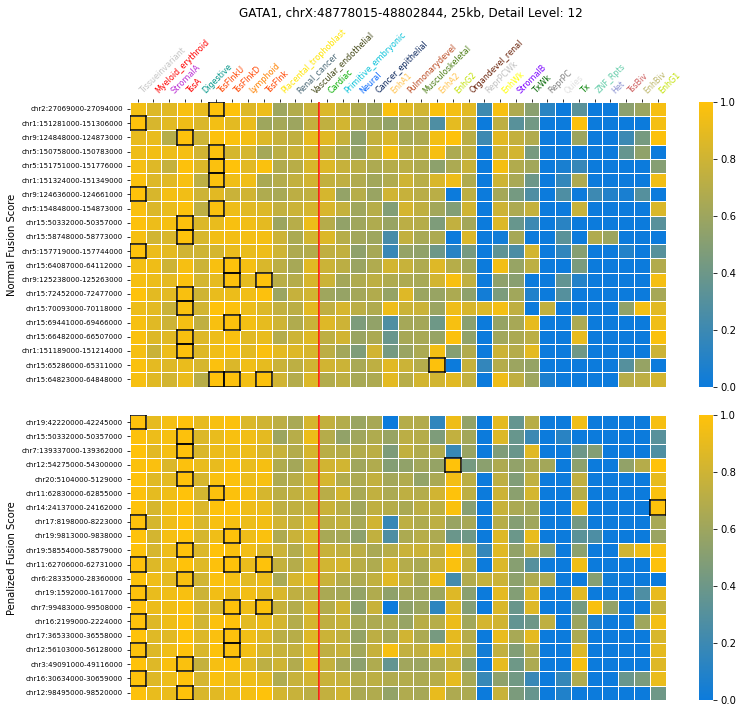

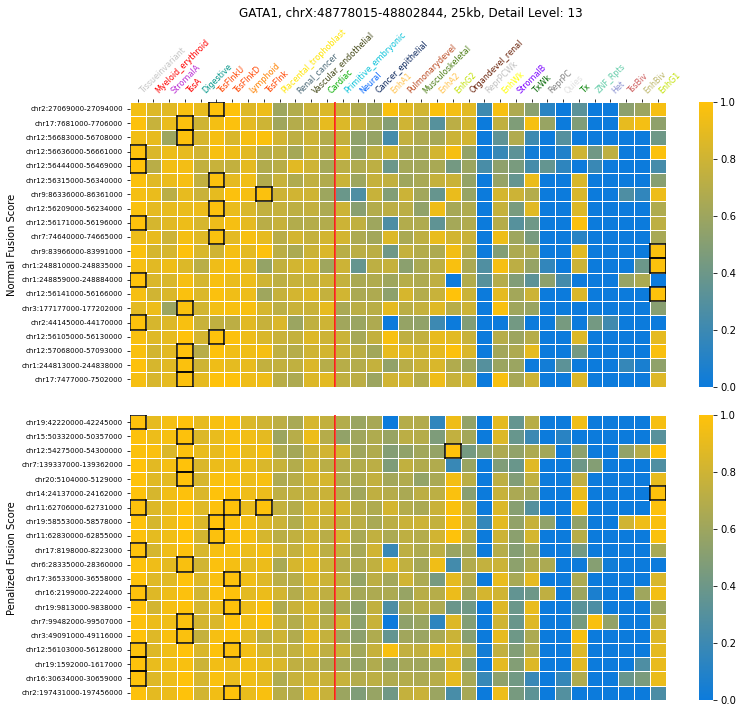

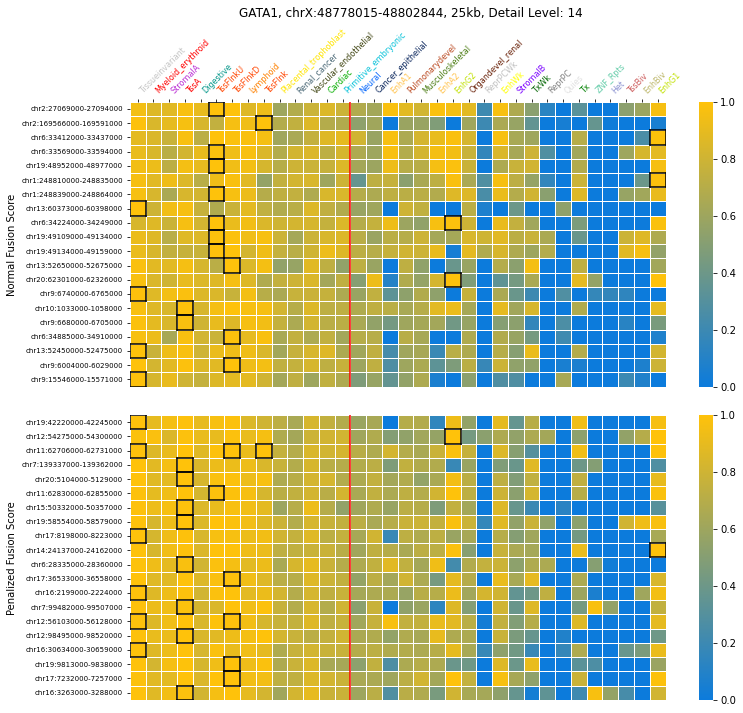

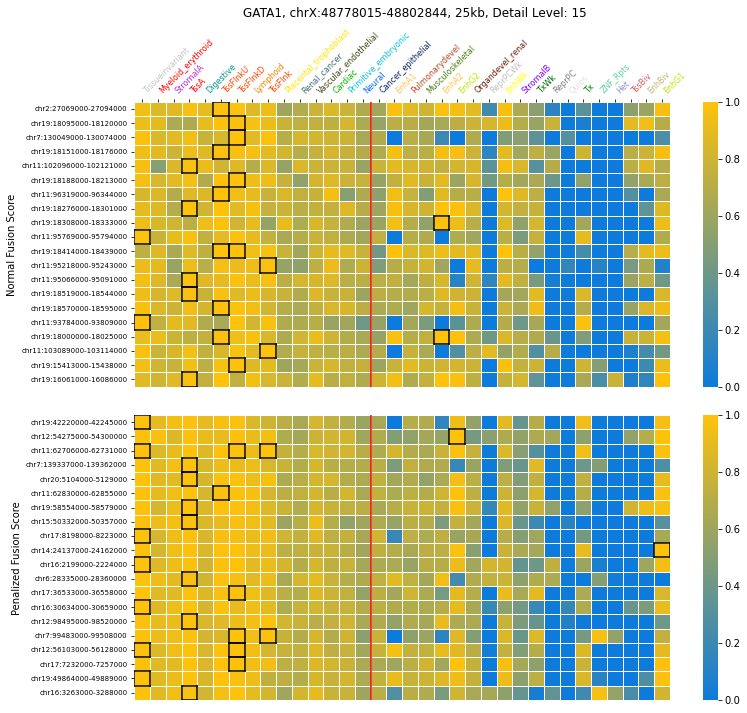

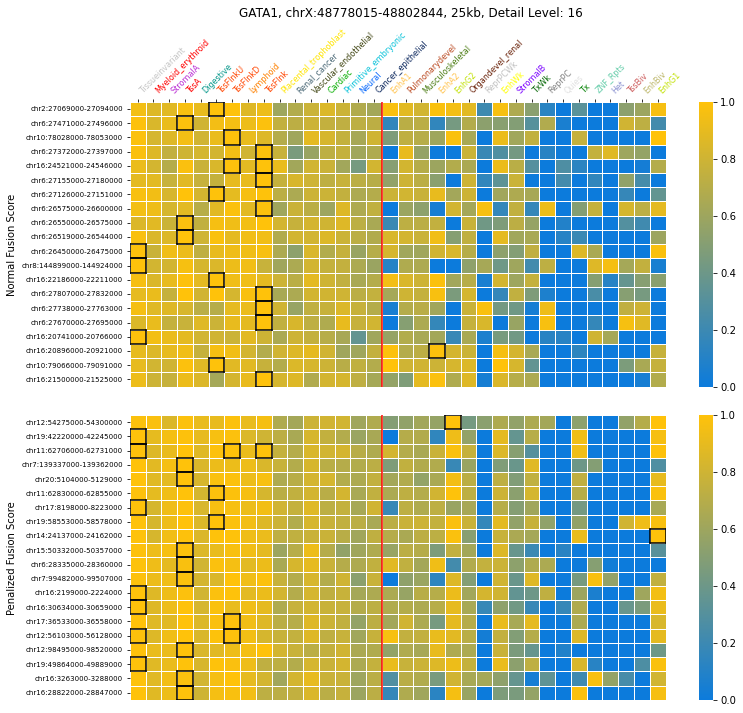

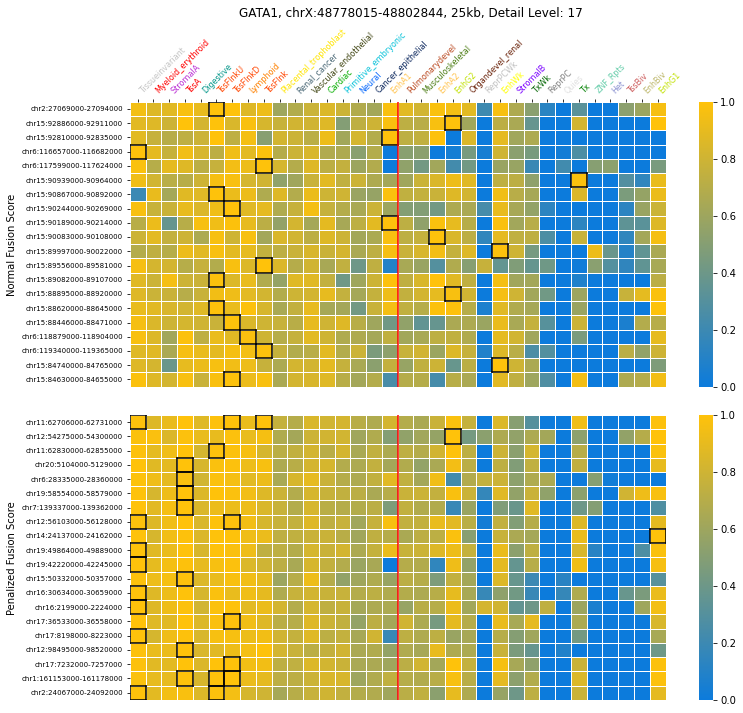

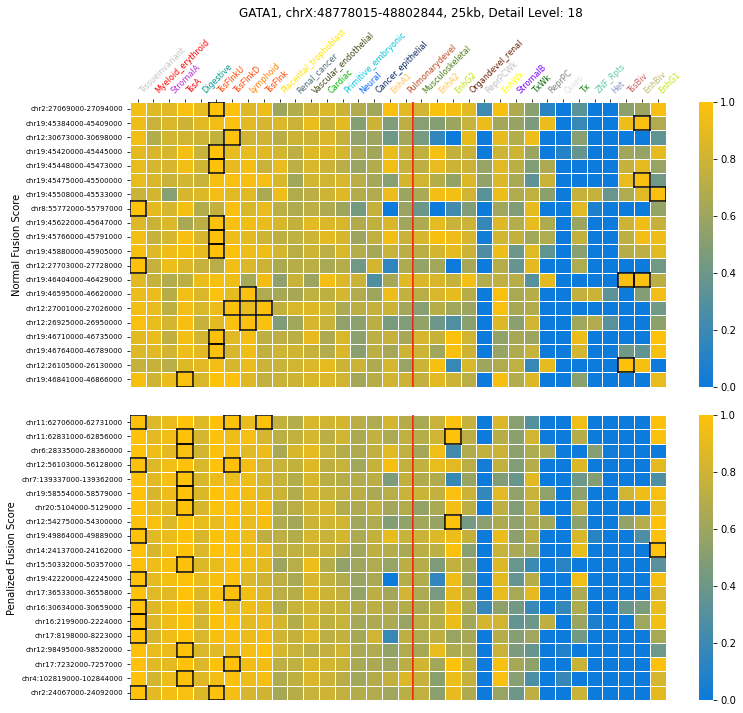

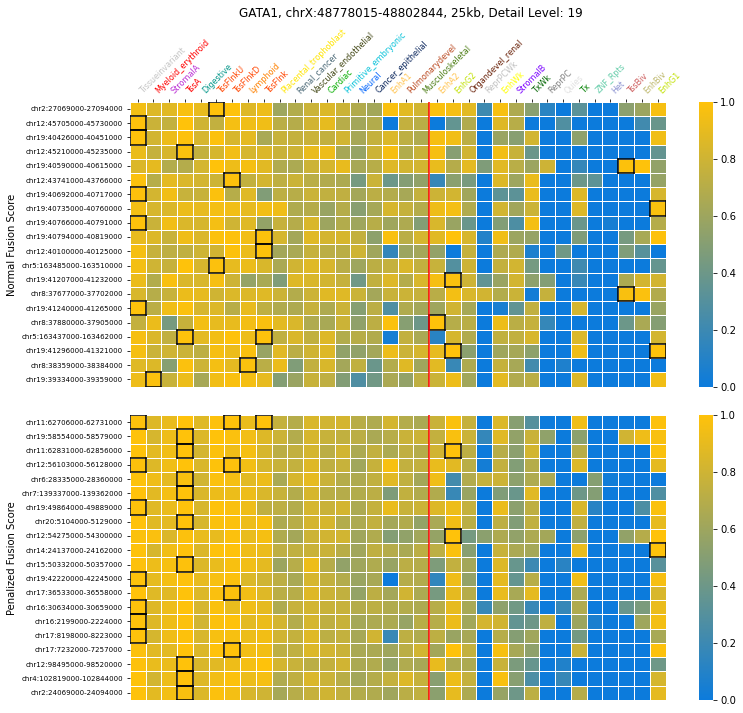

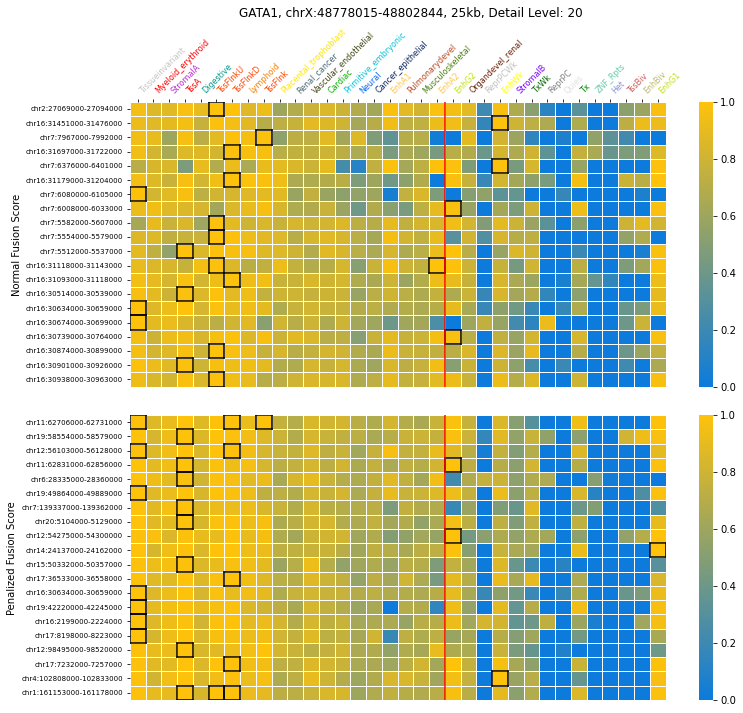

In [8]:
cm = LinearSegmentedColormap.from_list('yellowBlue', ["#0C7BDC", "#FFC20A"], N=1000)

query_per = s_sub[3][0, 0, :]
#initial detail level
dl = np.count_nonzero(query_per > np.sqrt(0.9))

# last detail level
dl = s_sub[3].shape[0]
# dl=1

for dl in range(1, s_sub[3].shape[0] + 1):

    fig, axes = plt.subplots(2, 1, figsize=(12, 11))  
    fig.patch.set_facecolor('white')
    plt.subplots_adjust(hspace=0.1)

    axes = axes.ravel()

    sns.heatmap(s_sub[3][dl-1, 1:, :][:, np.argsort(-query_per)], 
                ax=axes[0], 
                cmap=cm, 
                linewidths=1,
                vmin=0,
                vmax=1)
    # axes[0].set_xticks([])

    axes[0].xaxis.set_tick_params(labeltop=True, labelbottom=False, top=True, bottom=False)
    axes[0].set_xticklabels(factor_order[np.argsort(-query_per)], 
                            rotation=45, 
                            ha='left', 
                            fontsize=8)
    for label, c in zip(axes[0].xaxis.get_ticklabels(), color_order[np.argsort(-query_per)]):
            label.set_color(c)

    coord_list = []
    for coord_sep in s_sub[1][dl-1, 1:, :]:
        coord = coord_sep[0] + ':' + coord_sep[1] +'-' + coord_sep[2]
        coord_list.append(coord)
    axes[0].set_yticklabels(coord_list, fontsize=7, rotation=0)
    axes[0].set_ylabel('Normal Fusion Score')

    chosen_factors = chosen_factors_sub[s_sub[0][:, 1:]][dl-1]
    for cf, r in zip(chosen_factors, range(len(chosen_factors))):
        for cf_i in cf:
            cf_i_ordered = np.where(np.argsort(-query_per) == cf_i)[0][0]
            axes[0].plot([cf_i_ordered, cf_i_ordered], [r, r + 1], c='k')
            axes[0].plot([cf_i_ordered, cf_i_ordered + 1], [r + 1, r + 1], c='k')
            axes[0].plot([cf_i_ordered + 1, cf_i_ordered + 1], [r + 1, r], c='k')
            axes[0].plot([cf_i_ordered + 1, cf_i_ordered], [r, r], c='k')





    sns.heatmap(s_pen[3][dl-1, 1:, :][:, np.argsort(-query_per)], 
                ax=axes[1], 
                cmap=cm, 
                linewidths=1,
                vmin=0,
                vmax=1)
    axes[1].set_xticks([])


    coord_list = []
    for coord_sep in s_pen[1][dl-1, 1:, :]:
        coord = coord_sep[0] + ':' + coord_sep[1] +'-' + coord_sep[2]
        coord_list.append(coord)
    axes[1].set_yticklabels(coord_list, fontsize=7, rotation=0)
    axes[1].set_ylabel('Penalized Fusion Score')

    chosen_factors = chosen_factors_sub[s_pen[0][:, 1:]][dl-1]
    for cf, r in zip(chosen_factors, range(len(chosen_factors))):
        for cf_i in cf:
            cf_i_ordered = np.where(np.argsort(-query_per) == cf_i)[0][0]
            axes[1].plot([cf_i_ordered, cf_i_ordered], [r, r + 1], c='k')
            axes[1].plot([cf_i_ordered, cf_i_ordered + 1], [r + 1, r + 1], c='k')
            axes[1].plot([cf_i_ordered + 1, cf_i_ordered + 1], [r + 1, r], c='k')
            axes[1].plot([cf_i_ordered + 1, cf_i_ordered], [r, r], c='k')
            
    axes[0].plot([dl, dl], [0, 20], c='r')
    axes[1].plot([dl, dl], [0, 20], c='r')




    fig.suptitle(gene + ', ' + genomic_location + ', ' + scale + 'kb, Detail Level: ' + str(dl), x=0.45, y=1)
    
    plt.show()

**Trying with scaling ranks between -1 and 1**

In [ ]:
# simsearch(roi_percents, percents, roi, roi_coords, coords, included_factors, num_similar_regions)

In [70]:
percents = percents_sub
coords = coords_sub

In [71]:
# factors the query region ranks highest in
query_factor_order = np.argsort(-roi_percents)

# factors to search over
target_factors = query_factor_order[
    np.isin(query_factor_order, included_factors)
]

# convolution
roi_percents_targeted = roi_percents[target_factors]
roi_conv_all = percents[:, target_factors] * roi_percents_targeted

# fusion
roi_sim_all = []
for dl in range(1, len(included_factors) + 1):
    roi_sim = 1 - np.prod(1 - roi_conv_all[:, :dl], axis=1)
    roi_sim_all.append(roi_sim)
roi_sim_all = np.array(roi_sim_all)

Text(0.5, 1.0, 'Similarity Scores, Normal Fusion, All Regions with:\nGATA1, chrX:48778015-48802844, 25kb')

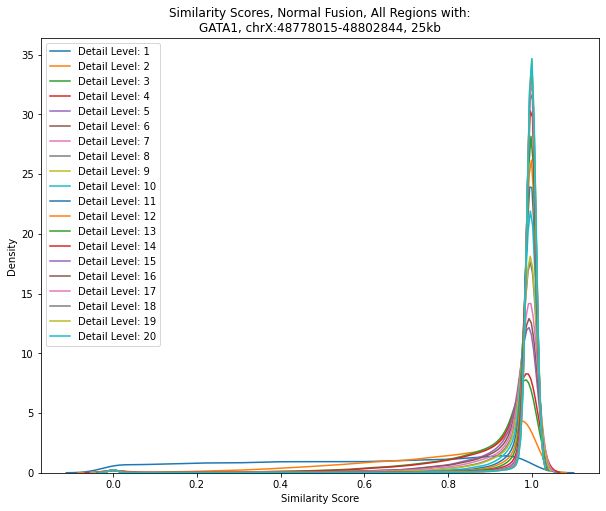

In [72]:
plt.figure(figsize=(10,8))
for i in range(roi_sim_all.shape[0]):
    sns.kdeplot(roi_sim_all[i, :])
    
plt.legend(np.char.add(np.array(['Detail Level: ']), 
                       (np.arange(roi_sim_all.shape[0]) + 1).astype(str)))
plt.xlabel('Similarity Score')

plt.title('Similarity Scores, Normal Fusion, All Regions with:\n' + gene + ', ' + genomic_location + ', ' + scale + 'kb')

In [73]:
# factors the query region ranks highest in
query_factor_order = np.argsort(-roi_percents)

# factors to search over
target_factors = query_factor_order[
    np.isin(query_factor_order, included_factors)
]

# convolution
roi_percents_targeted = roi_percents[target_factors]
# roi_conv_all = percents[:, target_factors] * roi_percents_targeted
roi_conv_all_penalty = ((percents[:, target_factors] * 2) - 1) * ((roi_percents_targeted * 2) - 1)

# fusion
roi_sim_all_penalty = []
for dl in range(1, len(included_factors) + 1):
    roi_sim = 1 - np.prod(1 - roi_conv_all_penalty[:, :dl], axis=1)
    roi_sim_all_penalty.append(roi_sim)
roi_sim_all_penalty = np.array(roi_sim_all_penalty)

Text(0.5, 1.0, 'Similarity Scores, Penalized Fusion, All Regions with:\nGATA1, chrX:48778015-48802844, 25kb')

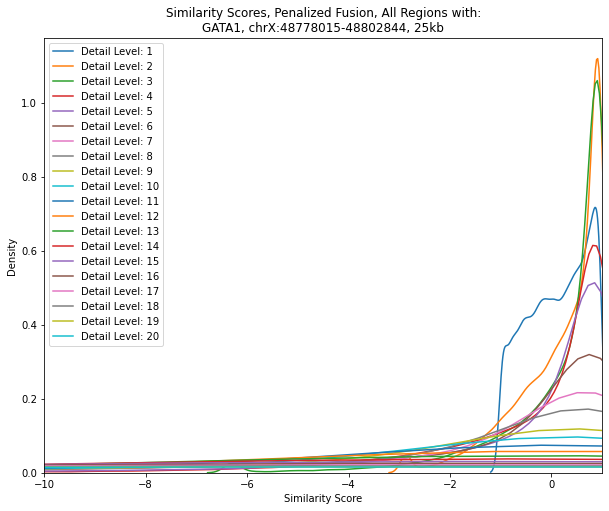

In [102]:
plt.figure(figsize=(10,8))
for i in range(roi_sim_all_penalty.shape[0]):
    sns.kdeplot(roi_sim_all_penalty[i, :])
    
plt.legend(np.char.add(np.array(['Detail Level: ']), 
                       (np.arange(roi_sim_all_penalty.shape[0]) + 1).astype(str)))
plt.xlabel('Similarity Score')
plt.xlim([-10, 1])

plt.title('Similarity Scores, Penalized Fusion, All Regions with:\n' + gene + ', ' + genomic_location + ', ' + scale + 'kb')

In [167]:
a = -1
b = 1
c = 0.5
1 - ((1 - a) * (1 - b) * (1 - c))

1.0

In [175]:
a = -1
b = 0.999
c = -1
1 - ((1 - a) * (1 - b) * (1 - c))

0.996

In [166]:
(1 - b)

0.5

In [26]:
0.7**2

0.48999999999999994

In [25]:
a1 = 0.7
a2 = 0.7
b1 = 0.7
b2 = 0.7
c1 = 0.7
c2 = 0.7

# I think the second method makes more sense (ie scale ranks, not convolution scores)
print(1 - ((1 - (a1*a2 * 2 - 1)) * (1 - (b1*b2 * 2 - 1)) * (1 - (c1*c2 * 2 - 1))))
print(1 - ((1 - ((a1 * 2 - 1) * (a2 * 2 - 1))) * (1 - ((b1 * 2 - 1) * (b2 * 2 - 1))) * (1 - ((c1 * 2 - 1) * (c2 * 2 - 1)))))

-0.06120799999999993
0.4072959999999999
